<a href="https://colab.research.google.com/github/drabastomek/datagen/blob/choice_sim/domino_draft.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [60]:
import cupy as cp
import cudf
import matplotlib.pyplot as plt


# The problem
Client: There should be 200 alternatives + 1 outside good. The outside good is always available. We'll make a slight change to how the other alternatives appear in the data. Their availability can be governed by independent binomial distributions with 50% probability. For each individual, 200 draws from a binomial distribution will correspond to the availability of the 200 alternatives. The key here is we want widely varying choice sets. Some users might be choosing between 3 options whereas others are choosing between 190 options.


### 1. Define the variables of our problem

In [61]:
print("Step 1: Defining the variables of our problem...")
n_alternatives = 200
n_alternatives_total = n_alternatives + 1 #including outside good
n_users = 100000
n_attributes_fixed = 40 #constants across all the individuals
n_attributes_varying = 5 #varies across all the individuals
n_attributes_random = 5 # completely random tastes/ options
n_nests = 67
epsilon = 1e-20  # Small constant to prevent division by zero, this was key!!


#total number of features
n_features = n_attributes_fixed + n_attributes_varying + n_attributes_random


Step 1: Defining the variables of our problem...


### 2. Create the features for the alternatives

In [62]:
print("Step 2: Creating the features for the alternatives...")
# Fixed features
# Shape: (n_alternatives, n_attributes_fixed)
features_fixed = cp.random.standard_normal(size=(n_alternatives, n_attributes_fixed))
features_varying = cp.random.standard_normal(size=(n_users, n_alternatives, n_attributes_varying))
features_for_random_coeffs = cp.random.standard_normal(size=(n_alternatives, n_attributes_random))


Step 2: Creating the features for the alternatives...


### 3. Calculate Coefficients

In [63]:
print("Step 3: Calculating coefficients...")
#coefficients for fixed and varying attributes
# Shape: (n_attributes_fixed + n_attributes_varying,)
coeffs_fixed_and_varying = cp.random.standard_normal(size=(n_attributes_fixed + n_attributes_varying,))
random_coeff_params = cp.random.standard_normal(size=(n_attributes_random, 2))
# Each of the 100 people gets their own set of 5 taste parameters
# Shape: (n_users, n_attributes_random)
coeffs_random = cp.array([cp.random.normal(loc=params[0], scale=cp.abs(params[1]), size=n_users) for params in random_coeff_params]).T
ASC = cp.random.standard_normal(size=n_alternatives)
ASC[0] = 0.0 # Normalize the first alternative's ASC to 0

Step 3: Calculating coefficients...


###Calculate Utility Components and Total Utility

In [64]:
print('Step 4: Calculating utility components and total utility...')
# utility of fixed attributes
# matmul and then broadcast the result across all decision-makers
# Shape: (n_users, n_alternatives)
utility_fixed = cp.matmul(features_fixed, coeffs_fixed_and_varying[:n_attributes_fixed])
utility_fixed = cp.broadcast_to(utility_fixed, (n_users, n_alternatives))

utility_varying = cp.matmul(features_varying, coeffs_fixed_and_varying[n_attributes_fixed:]).squeeze()
# utility from random coefficients (tastes)

# cupy.einsum for a clean, vectorized multiplication and sum( user * coef and alt * coef)
# Shape: (n_decision_makers, n_alternatives)
utility_random = cp.einsum('ij,kj->ik', coeffs_random, features_for_random_coeffs)
# Add the error term for randomness in choice
# Shape: (n_decision_makers, n_alternatives)
error_term = cp.random.gumbel(size=(n_users, n_alternatives))
#total utility of inside good
total_utility_inside = cp.random.randn(n_users, n_alternatives, dtype=cp.float64)
total_utility = utility_fixed + utility_varying + utility_random + error_term + ASC


Step 4: Calculating utility components and total utility...


Now we need to add out 'outside' alternative. To calculate this, we will use the following formula

$$
V_{\mathtt{outside}} = \ln\Bigg(\frac{p}{1-p}\sum_i \exp^{V_{i}}\Bigg) \\
$$
where $p$ is the probability of selecting the $\mathtt{outside}$ alternative.

In [65]:
# calculation the final utility matrix
# This is the V_ij that feeds into the nested logit formulas
# Shape: (n_decision_makers, n_alternatives)
print("Step 5:Simulating the choices using Nest Logit Model...")
# unique availability matrix for each person.
p_avail = cp.random.beta(2, 4, size=(n_users, 1))
availability_matrix = cp.random.binomial(1, p_avail, size=(n_users, n_alternatives))
# use the availability
#exp(utility) is zero, so it doesn't contribute to the probabilities.
utility_avail = cp.where(availability_matrix == 1, total_utility, -cp.inf)


# Define the nesting structure and coefficients
nest_membership = cp.zeros((n_alternatives, n_nests), dtype=cp.int32)
nest_indices = cp.concatenate([cp.repeat(cp.arange(n_nests - 1), 3), cp.array([n_nests - 1] * 2)])
nest_membership[cp.arange(n_alternatives), nest_indices] = 1
nest_coeffs = cp.random.rand(n_nests)



# Calculate the inclusive value for each nest
lambdas = cp.matmul(nest_membership, nest_coeffs)
utility_scaled_nest = utility_avail / lambdas
inclusive_values = nest_coeffs * cp.log(cp.matmul(cp.exp(utility_scaled_nest), nest_membership) + epsilon)

outside_alternative = 0.9 #constant
multiplier = outside_alternative / (1 - outside_alternative)
#Calculate the utility of the outside good.
sum_exp_iv = cp.sum(cp.exp(inclusive_values), axis=1)
utility_outside = cp.log(multiplier * sum_exp_iv + epsilon)

# Combine inclusive values and outside good utility
#handle the -inf values in inclusive_values before exponentiation
combined_utilities = cp.concatenate([inclusive_values, utility_outside[:, None]], axis=1)

#final probabilities using the same logic as before.
denominator = sum_exp_iv + cp.exp(utility_outside)
prob_nests = cp.exp(inclusive_values) / (denominator[:, None]+ epsilon)
prob_outside_good = cp.exp(utility_outside) / denominator

sum_exp_utility_nests_broadcasted = cp.matmul(
    cp.matmul(cp.exp(utility_scaled_nest), nest_membership),
    nest_membership.T
)
prob_alt_in_nest = cp.exp(utility_scaled_nest) / (sum_exp_utility_nests_broadcasted +epsilon)
unconditional_prob = prob_alt_in_nest * cp.matmul(prob_nests, nest_membership.T)

# Combine the probabilities
final_probabilities = cp.concatenate([unconditional_prob, prob_outside_good[:, None]], axis=1)
#error check for nan/if values
final_probabilities = cp.nan_to_num(final_probabilities, nan=0.0)
final_probabilities /= (cp.sum(final_probabilities, axis=1, keepdims=True) + epsilon)
final_probabilities

#simulate the choices

sum_probs = cp.cumsum(final_probabilities, axis=1)

random_draw = cp.random.rand(n_users, 1)

choices = cp.argmax(sum_probs > random_draw, axis=1)


Step 5:Simulating the choices using Nest Logit Model...


## Find the IV

P(alt) = P(alt | nest) * P(nest)

Calculating the cumulative proablity distribution, draw a single number per user, and use argmax to find the first alt with cum_prob > random

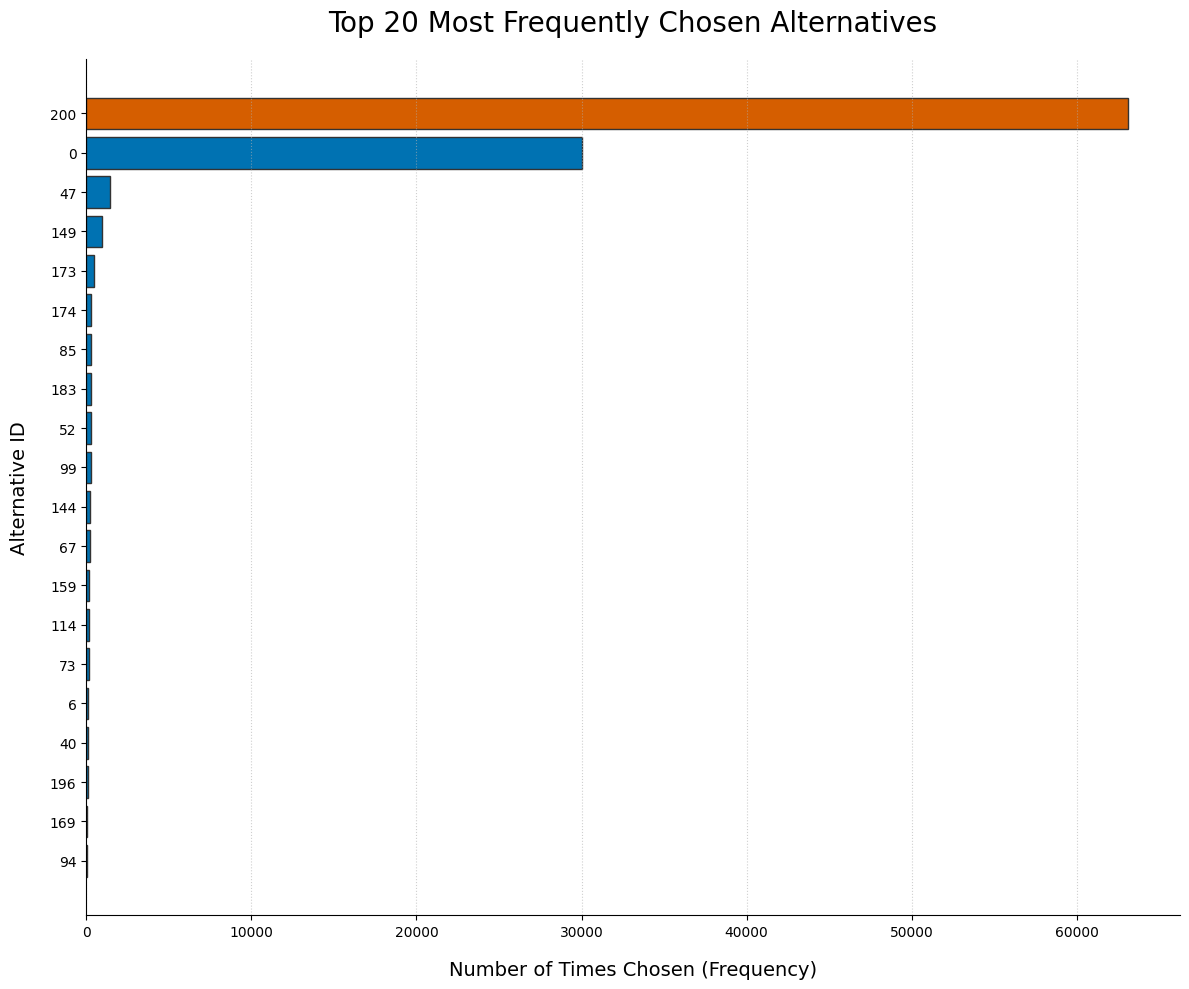

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import cupy as cp

# Assuming 'choices' is a cupy array from the previous steps
choices_s = pd.Series(choices.get(), name='counts')

# --- Data Preparation for a Top N Chart ---
# Calculate the frequency of each choice
choice_counts = choices_s.value_counts()

# Get the Top 20 most frequent choices. Use nlargest.
top_n = 20
top_choices = choice_counts.nlargest(top_n).sort_values(ascending=True)

# --- Graph Customization ---
main_color = '#0072B2'
outside_good_color = '#D55E00'
edge_color = '#333333'

# Check if the outside good is in the top choices to color it differently
colors = [outside_good_color if i == n_alternatives else main_color for i in top_choices.index]

# Create the plot
plt.figure(figsize=(12, 10)) # Adjusted for a vertical layout
# Use plt.barh() for a horizontal bar chart
plt.barh(range(len(top_choices)), top_choices.values, color=colors, edgecolor=edge_color)

# --- Titles and Labels ---
plt.title(f'Top {top_n} Most Frequently Chosen Alternatives', fontsize=20, pad=20)
plt.xlabel('Number of Times Chosen (Frequency)', fontsize=14, labelpad=15)
plt.ylabel('Alternative ID', fontsize=14, labelpad=15)

# --- Ticks and Layout ---
# Use the alternative IDs as the y-tick labels
plt.yticks(range(len(top_choices)), top_choices.index)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
# Add a grid for easier value reading
plt.grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

##Storing the data

In [67]:
print("Step 6: Storing the data...")

# Create user and alt IDs corresponding to the flattened data
user_ids = cp.repeat(cp.arange(n_users), n_alternatives)
alt_ids = cp.tile(cp.arange(n_alternatives),n_users)
asc_tiled = cp.tile(ASC, n_users)

#storing the choices to a parquet file
choices_store =cudf.DataFrame(choices, columns=["choice",]).reset_index()
choices_store.rename(columns={"index": "user_id"}, inplace=True)

#storing the coefficients
coeff_store = cudf.DataFrame(coeffs_fixed_and_varying, columns=["coeffs",]).reset_index()
coeff_store.rename(columns={"index": "attribute_id"}, inplace=True)

flat_fixed_utility = utility_fixed.flatten()
flat_varying_utility = utility_varying.flatten()
flat_random_utility = utility_random.flatten()
flat_total_utility = total_utility.flatten()


alt_attributes_store = cudf.DataFrame({
    'user_id': user_ids,
    'alt_id': alt_ids,
    'flat_fixed_utility': flat_fixed_utility,
    'flat_varying_utility':flat_varying_utility,
    'flat_random_utility':flat_random_utility,
    'flat_total_utility':flat_total_utility,
    'asc':asc_tiled
}
)




Step 6: Storing the data...


In [68]:
print('Step 7: Saving results to Parquet')
#creating the files
coeff_store.to_parquet("coeffs.parquet", index=False)
choices_store.to_parquet("choices.parquet", index=False)
alt_attributes_store.to_parquet("alt_attributes.parquet", index=False)

print("\nScript executed successfully.")


Step 7: Saving results to Parquet

Script executed successfully.


## Create the script automation

In [74]:
#create the config file
import yaml
import subprocess
import sys
config_data = {
    'parameters': {
        'n_users': 100000,
        'n_alternatives': 200,
        'random_seed':2025
    },
    'features':{
        'n_attributes_fixed': 40,
        'n_attributes_varying': 5,
        'n_attributes_random': 5,
    },
    'simulation':{
        'n_nests': 67,
        'outside_good_prob':0.9,
        'availability_beta_a':2.0,
        'availability_beta_b':4.0,
        'epsilon':1e-20
    },
    'outputs': {
        'output_file': 'outputs/',
        'coeffs_file': 'coeffs.parquet',
        'choices_file': 'choices.parquet',
        'alt_attributes_file': 'alt_attributes.parquet'

    }
}
config_file_path = 'config.yaml'

In [75]:
def create_config_file():
  print(f" Step 1: Creating config file: {config_file_path}---")
  try:
    with open(config_file_path, 'w') as file:
      yaml.dump(config_data, file, sort_keys=False)
    print(f"Successfully created config file at: {config_file_path}")

  except Exception as e:
    print(f"Error creating config file: {e}")
    sys.exit(1)

#execute the script
def run_simulation():
  print(f"Step 2: Run the main simulation script")
  try:
    command = [sys.executable, 'main.py','--config' , config_file_path]
    #error checking
    subprocess.run(command, check=True,
                   capture_output=True,
                   text=True)
  except subprocess.CalledProcessError as e:
    print(f"Error running simulation script: {e}")
    print("Error Output (stderr):\n", e.stderr)
    sys.exit(1)
if __name__ == "__main__":
  create_config_file()
  run_simulation()
  print('\n--- Simulation finished. ---')

 Step 1: Creating config file: config.yaml---
Successfully created config file at: config.yaml
Step 2: Run the main simulation script

--- Simulation finished. ---


In [76]:

%%writefile main.py
import cupy as cp
import cudf
import yaml
import argparse
import os

def load_config(config_path):
    with open(config_path, 'r') as file:
        config = yaml.safe_load(file)
    return config

def run_simulation(config):
    # Extract parameters from config
    params = config['parameters']
    features_config = config['features']
    simulation_config = config['simulation']
    outputs_config = config['outputs']

    n_users = params['n_users']
    n_alternatives = params['n_alternatives']
    n_attributes_fixed = features_config['n_attributes_fixed']
    n_attributes_varying = features_config['n_attributes_varying']
    n_attributes_random = features_config['n_attributes_random']
    n_nests = simulation_config['n_nests']
    outside_good_prob = simulation_config['outside_good_prob']
    availability_beta_a = simulation_config['availability_beta_a']
    availability_beta_b = simulation_config['availability_beta_b']
    epsilon = simulation_config['epsilon']
    random_seed = params.get('random_seed', None) # Optional random seed

    if random_seed is not None:
        cp.random.seed(random_seed)

    n_alternatives_total = n_alternatives + 1
    n_features = n_attributes_fixed + n_attributes_varying + n_attributes_random

    print("Step 1: Defining the variables of our problem...")
    print("Step 2: Creating the features for the alternatives...")
    # Fixed features
    features_fixed = cp.random.standard_normal(size=(n_alternatives, n_attributes_fixed))
    features_varying = cp.random.standard_normal(size=(n_users, n_alternatives, n_attributes_varying))
    features_for_random_coeffs = cp.random.standard_normal(size=(n_alternatives, n_attributes_random))

    print("Step 3: Calculating coefficients...")
    #coefficients for fixed and varying attributes
    coeffs_fixed_and_varying = cp.random.standard_normal(size=(n_attributes_fixed + n_attributes_varying,))
    random_coeff_params = cp.random.standard_normal(size=(n_attributes_random, 2))
    coeffs_random = cp.array([cp.random.normal(loc=params[0], scale=cp.abs(params[1]), size=n_users) for params in random_coeff_params]).T
    ASC = cp.random.standard_normal(size=n_alternatives)
    ASC[0] = 0.0 # Normalize the first alternative's ASC to 0

    print('Step 4: Calculating utility components and total utility...')
    # utility of fixed attributes
    utility_fixed = cp.matmul(features_fixed, coeffs_fixed_and_varying[:n_attributes_fixed])
    utility_fixed = cp.broadcast_to(utility_fixed, (n_users, n_alternatives))

    utility_varying = cp.matmul(features_varying, coeffs_fixed_and_varying[n_attributes_fixed:]).squeeze()
    # utility from random coefficients (tastes)
    utility_random = cp.einsum('ij,kj->ik', coeffs_random, features_for_random_coeffs)
    # Add the error term for randomness in choice
    error_term = cp.random.gumbel(size=(n_users, n_alternatives))
    total_utility = utility_fixed + utility_varying + utility_random + error_term + ASC

    print("Step 5:Simulating the choices using Nest Logit Model...")
    # unique availability matrix for each person.
    p_avail = cp.random.beta(availability_beta_a, availability_beta_b, size=(n_users, 1))
    availability_matrix = cp.random.binomial(1, p_avail, size=(n_users, n_alternatives))
    # use the availability
    utility_avail = cp.where(availability_matrix == 1, total_utility, -cp.inf)

    # Define the nesting structure and coefficients
    nest_membership = cp.zeros((n_alternatives, n_nests), dtype=cp.int32)
    # Ensure nest_indices creation logic is correct based on n_alternatives and n_nests
    # For simplicity, let's assume a simple nesting structure for this example
    # In a real scenario, this would likely need to be defined more carefully
    alts_per_nest = n_alternatives // n_nests
    remainder = n_alternatives % n_nests
    nest_sizes = [alts_per_nest] * n_nests
    for i in range(remainder):
        nest_sizes[i] += 1

    current_alt = 0
    for nest_idx, size in enumerate(nest_sizes):
        nest_membership[current_alt:current_alt + size, nest_idx] = 1
        current_alt += size


    nest_coeffs = cp.random.rand(n_nests)

    # Calculate the inclusive value for each nest
    lambdas = cp.matmul(nest_membership, nest_coeffs)
    utility_scaled_nest = utility_avail / lambdas
    inclusive_values = nest_coeffs * cp.log(cp.matmul(cp.exp(utility_scaled_nest), nest_membership) + epsilon)

    multiplier = outside_good_prob / (1 - outside_good_prob)
    #Calculate the utility of the outside good.
    sum_exp_iv = cp.sum(cp.exp(inclusive_values), axis=1)
    utility_outside = cp.log(multiplier * sum_exp_iv + epsilon)

    # Combine inclusive values and outside good utility
    combined_utilities = cp.concatenate([inclusive_values, utility_outside[:, None]], axis=1)

    #final probabilities using the same logic as before.
    denominator = sum_exp_iv + cp.exp(utility_outside)
    prob_nests = cp.exp(inclusive_values) / (denominator[:, None]+ epsilon)

    # Calculate probability of alternative conditional on being in a nest
    # This requires carefully handling the case where the sum of exp(utility_scaled_nest) in a nest is zero
    sum_exp_utility_nests = cp.matmul(cp.exp(utility_scaled_nest), nest_membership)
    # Avoid division by zero by adding epsilon
    sum_exp_utility_nests_safe = sum_exp_utility_nests + epsilon
    # Expand sum_exp_utility_nests_safe to match utility_scaled_nest shape for division
    sum_exp_utility_nests_expanded = cp.matmul(sum_exp_utility_nests_safe, nest_membership.T)

    prob_alt_in_nest = cp.exp(utility_scaled_nest) / sum_exp_utility_nests_expanded

    unconditional_prob = prob_alt_in_nest * cp.matmul(prob_nests, nest_membership.T)

    # Probability of outside good
    prob_outside_good = cp.exp(utility_outside) / (denominator + epsilon)


    # Combine the probabilities (including outside good)
    final_probabilities = cp.concatenate([unconditional_prob, prob_outside_good[:, None]], axis=1)
    #error check for nan/if values
    final_probabilities = cp.nan_to_num(final_probabilities, nan=0.0)
    final_probabilities /= (cp.sum(final_probabilities, axis=1, keepdims=True) + epsilon)


    #simulate the choices
    sum_probs = cp.cumsum(final_probabilities, axis=1)
    random_draw = cp.random.rand(n_users, 1)
    choices = cp.argmax(sum_probs > random_draw, axis=1)

    print("Step 6: Storing the data...")
    # Create user and alt IDs corresponding to the flattened data
    user_ids = cp.repeat(cp.arange(n_users), n_alternatives)
    alt_ids = cp.tile(cp.arange(n_alternatives),n_users)
    asc_tiled = cp.tile(ASC, n_users)

    #storing the choices to a parquet file
    choices_store =cudf.DataFrame(choices, columns=["choice",]).reset_index()
    choices_store.rename(columns={"index": "user_id"}, inplace=True)

    #storing the coefficients
    coeff_store = cudf.DataFrame(coeffs_fixed_and_varying, columns=["coeffs",]).reset_index()
    coeff_store.rename(columns={"index": "attribute_id"}, inplace=True)

    flat_fixed_utility = utility_fixed.flatten()
    flat_varying_utility = utility_varying.flatten()
    flat_random_utility = utility_random.flatten()
    flat_total_utility = total_utility.flatten()

    alt_attributes_store = cudf.DataFrame({
        'user_id': user_ids,
        'alt_id': alt_ids,
        'flat_fixed_utility': flat_fixed_utility,
        'flat_varying_utility':flat_varying_utility,
        'flat_random_utility':flat_random_utility,
        'flat_total_utility':flat_total_utility,
        'asc':asc_tiled
    })

    print('Step 7: Saving results to Parquet')

    output_dir = outputs_config['output_file']
    os.makedirs(output_dir, exist_ok=True)

    coeff_store.to_parquet(os.path.join(output_dir, outputs_config['coeffs_file']), index=False)
    choices_store.to_parquet(os.path.join(output_dir, outputs_config['choices_file']), index=False)
    alt_attributes_store.to_parquet(os.path.join(output_dir, outputs_config['alt_attributes_file']), index=False)

    print("\nScript executed successfully.")


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Run discrete choice simulation.")
    parser.add_argument('--config', type=str, required=True,
                        help='Path to the configuration YAML file')
    args = parser.parse_args()

    config = load_config(args.config)
    run_simulation(config)


Overwriting main.py


In [77]:
%%python3 main.py --config config.yaml

Step 1: Defining the variables of our problem...
Step 2: Creating the features for the alternatives...
Step 3: Calculating coefficients...
Step 4: Calculating utility components and total utility...
Step 5:Simulating the choices using Nest Logit Model...
Step 6: Storing the data...
Step 7: Saving results to Parquet

Script executed successfully.


error checking

In [79]:
import cudf
import yaml


# --- Verify choices.parquet ---
print("--- Verifying choices.parquet ---")
choices_df = cudf.read_parquet( 'outputs/choices.parquet')
print(f"Shape: {choices_df.shape}") # Should be (n_users, 2)
print("Columns:", choices_df.columns.to_list())
print("Head:\n", choices_df.head())
print("\n" + "="*40 + "\n")


# --- Verify coeffs.parquet ---
print("--- Verifying coeffs.parquet ---")
coeffs_df = cudf.read_parquet('outputs/coeffs.parquet')
print(f"Shape: {coeffs_df.shape}") # Should be (n_attributes_fixed + n_attributes_varying, 2)
print("Columns:", coeffs_df.columns.to_list())
print("Head:\n", coeffs_df.head())
print("\n" + "="*40 + "\n")


# --- Verify alt_attributes.parquet ---
print("--- Verifying alt_attributes.parquet ---")
attributes_df = cudf.read_parquet('outputs/alt_attributes.parquet')
# This is a key check: rows should equal n_users * n_alternatives
print(f"Shape: {attributes_df.shape}")
print("Columns:", attributes_df.columns.to_list())
print("Head:\n", attributes_df.head())
print("\n" + "="*40 + "\n")

# --- Verify config.yaml ---
print("--- Verifying config.yaml ---")
with open('config.yaml', 'r') as f:
    config_run = yaml.safe_load(f)

# Print a key parameter to confirm it's the right config
print(f"The number of users in this run was: {config_run['parameters']['n_users']}")

--- Verifying choices.parquet ---
Shape: (100000, 2)
Columns: ['user_id', 'choice']
Head:
    user_id  choice
0        0     200
1        1     200
2        2     200
3        3     200
4        4     200


--- Verifying coeffs.parquet ---
Shape: (45, 2)
Columns: ['attribute_id', 'coeffs']
Head:
    attribute_id    coeffs
0             0 -1.221347
1             1 -0.311704
2             2 -0.443190
3             3 -0.813737
4             4  0.167302


--- Verifying alt_attributes.parquet ---
Shape: (20000000, 7)
Columns: ['user_id', 'alt_id', 'flat_fixed_utility', 'flat_varying_utility', 'flat_random_utility', 'flat_total_utility', 'asc']
Head:
    user_id  alt_id  flat_fixed_utility  flat_varying_utility  \
0        0       0            1.538705              0.727794   
1        0       1            5.063881             -0.812907   
2        0       2            1.050331              0.860161   
3        0       3            2.111532              0.433005   
4        0       4        